In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from core.rings_calc import k_symmetric, expected_dissipation_ring, compute_asymmetric_case_from_sigma
from core import figstyle

# Symmetry breaking in ring networks driven by renewable generation time series.

We consider a network belonging to the ring class with $N=3$, where every node corresponds to a geographical region. Regions $i=2,4,6$ consume power such that the injection can be written as $S_i = -\mu$. Region $i=1$ features wind turbines and region $i=3$ features solar photovoltaic plants, such that power generation at a time $t$ can be written as
\begin{align*}
    S_1(t) &= (1-\zeta) \mu + \zeta \mu Z_1(t), \\
    S_3(t) &= (1-\zeta) \mu + \zeta \mu Z_3(t),
\end{align*}
where $Z_1$ and $Z_3$ denote the normalized capacity factors of a wind turbine or solar PV plant and the parameter $\zeta \in [0,1]$ measures the share of fluctuating renewable power generation.

The capacity factor is defined as the ratio of the actual power generation at time $t$ divided by the maximum generation. Here, we rescale the capacity factor by a constant number such that $\braket{Z_1} = 1 =\braket{Z_3}$.

Finally, we assume that region $5$ hosts storage infrastructures that provide or consume the power $S_5(t) = 3\mu - S_1(t) - S_3(t)$.

In [2]:
def load_capacity_factors(solar_file, wind_file):
    """
    Load and normalize renewable generation time series.
    Reads solar and wind power generation data from CSV files and rescales
    each time series to unit mean, yielding normalized capacity factors.
    """
    solar = pd.read_csv(solar_file)["electricity"].values
    wind  = pd.read_csv(wind_file)["electricity"].values

    solar = solar / np.mean(solar)
    wind  = wind  / np.mean(wind)

    return solar, wind

def compute_renewable_second_moments(solar, wind):
    """
    Compute second-moment matrices for renewable-driven injections.

    Constructs the empirical second moments of the stochastic injections
    in a six-node ring network with wind (node 1), solar (node 3), and a
    balancing source (node 5). The total covariance is decomposed into
    contributions from fluctuating and deterministic components.
    """
    
    T = len(solar)

    # Fluctuating source terms: node 1 = wind, node 3 = solar, node 5 = balancing source
    X1 = [wind, -np.ones(T), solar, -np.ones(T), 3 - wind - solar, -np.ones(T)]

    # Deterministic mean injection pattern
    X2 = [np.ones(T), -np.ones(T), np.ones(T), -np.ones(T), np.ones(T), -np.ones(T)]

    smm11 = np.zeros((6, 6))
    smm12 = np.zeros((6, 6))
    smm22 = np.zeros((6, 6))

    for i in range(6):
        for j in range(6):
            smm11[i, j] = np.mean(X1[i] * X1[j])
            smm12[i, j] = np.mean(X1[i] * X2[j]) + np.mean(X2[i] * X1[j])
            smm22[i, j] = np.mean(X2[i] * X2[j])

    return smm11, smm12, smm22

def symmetric_network_dissipation(N, gamma, Sigma, kappa=1.0):
    """ Compute the dissipation and capacities for the symmetric network configuration."""
    k_sym = k_symmetric(N, gamma, kappa=kappa)
    D_sym = expected_dissipation_ring(N, k_sym, Sigma)
    
    return D_sym, k_sym

def compute_capacity_scan(N, gamma_values, zeta_values, solar_file, wind_file):
    solar, wind = load_capacity_factors(solar_file, wind_file)
    smm11, smm12, smm22 = compute_renewable_second_moments(solar, wind)

    capacity_values = np.zeros((len(zeta_values), len(gamma_values)))
    total_points = len(zeta_values) * len(gamma_values)
    point_counter = 0

    for i, zeta in enumerate(zeta_values):
        Sigma = (zeta**2 * smm11 + (1 - zeta)**2 * smm22 + zeta * (1 - zeta) * smm12)

        for j, gamma in enumerate(gamma_values):
            point_counter += 1
            print(f"[{point_counter}/{total_points}] ({i}, {j})", end="\r", flush=True)

            # Symmetric closed ring
            best_D, best_k = symmetric_network_dissipation(N, gamma, Sigma)

            # Test all shifted strongly broken open-ring states
            for shift in range(2 * N):
                Sigma_shift = np.roll(Sigma, shift, axis=0)
                Sigma_shift = np.roll(Sigma_shift, shift, axis=1)

                D_brk, k_brk = compute_asymmetric_case_from_sigma(N, gamma, Sigma_shift, kappa=1.0, broken_edge=-1)

                if D_brk < best_D:
                    best_D = D_brk
                    best_k = k_brk

            capacity_values[i, j] = np.min(best_k)

    print()
    return capacity_values

We now compute the optimal network structure for a renewable-driven ring network.

We consider the six-node ring (N = 3) with stochastic injections derived from wind and solar time series. The second-moment matrix Sigma is constructed as a convex combination of fluctuating and deterministic components, controlled by the parameter zeta (share of renewable fluctuations).

For each $(\gamma, \zeta)$, we compare:
    - the symmetric closed-ring solution
    - all strongly symmetry-broken open-ring configurations (via cyclic shifts)

In [3]:
N = 3

gamma_values = np.linspace(0.3, 1.0, 400)
zeta_values = np.linspace(0.0, 1.0, 400)

capacity_values = np.zeros((len(zeta_values), len(gamma_values)))

solar_file = "energy_data/ninja_pv_50.9221_6.3611_corrected.csv"
wind_file = "energy_data/ninja_wind_50.9221_6.3611_corrected.csv"

capacity_path = f"scan_data/capacity_scan_N{N}_g{len(gamma_values)}_z{len(zeta_values)}.npz"

# Load cached scan if it exists and matches the current grid, otherwise compute and save
cache_ok = False
try:
    d = np.load(capacity_path)
    cache_ok = (
        int(d["N"]) == N
        and np.array_equal(d["gamma_values"], gamma_values)
        and np.array_equal(d["zeta_values"], zeta_values)
    )
    if cache_ok:
        capacity_values = d["capacity_values"]
    else:
        print(f"Cached file {capacity_path} does not match current parameters, recomputing.")
except FileNotFoundError:
    pass

if not cache_ok:
    capacity_values = compute_capacity_scan(N, gamma_values, zeta_values, solar_file, wind_file)
    np.savez(capacity_path, N=N, gamma_values=gamma_values, zeta_values=zeta_values,
             capacity_values=capacity_values, solar_file=solar_file, wind_file=wind_file)

[160000/160000] (399, 399)


# Figure 6

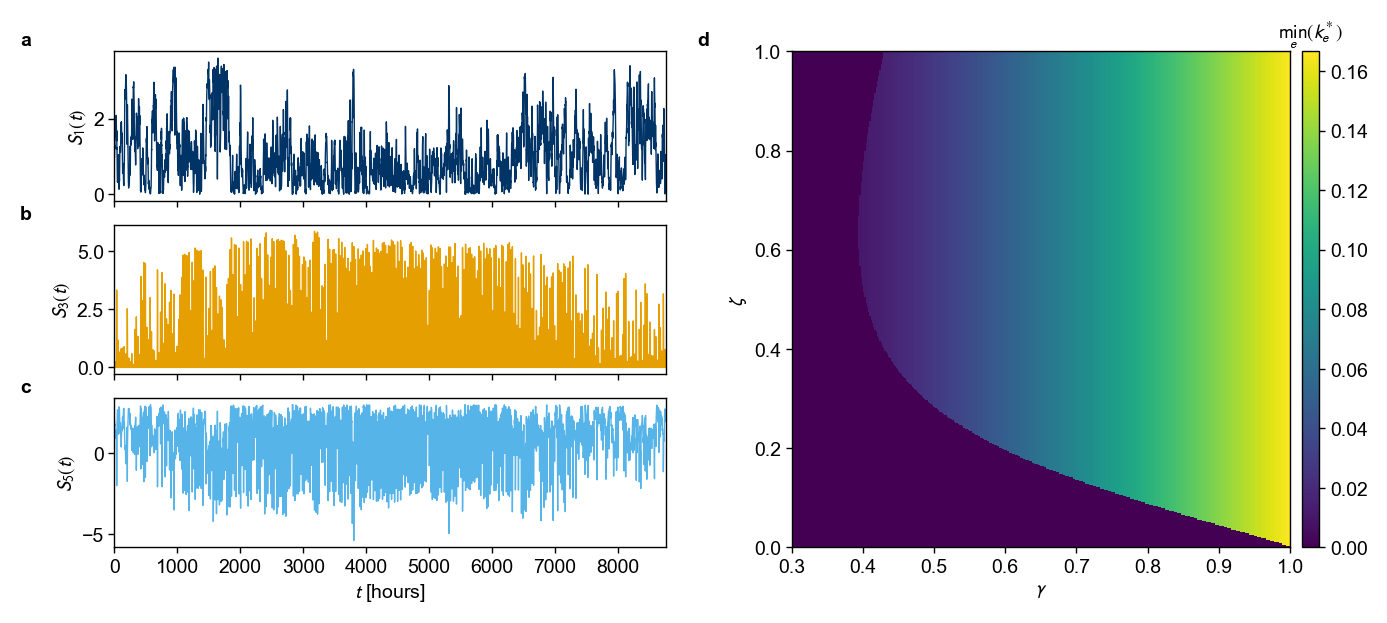

In [4]:
# Figure: renewable-driven ring network
# Panels a-c are the injection time series, d the phase diagram
figstyle.apply()

# Define system parameters
zeta = 1.0
mu = 1.0

solar, wind = load_capacity_factors(solar_file, wind_file)

Z1 = wind
Z3 = solar
Z5 = 3.0 - wind - solar

S1 = (1 - zeta) * mu + zeta * mu * Z1
S3 = (1 - zeta) * mu + zeta * mu * Z3
S5 = 3 * mu - S1 - S3

t = np.arange(len(S1))

width, height = 179.0, 82.0
left, right = 15.0, 11.0
avail = width - left - right

col_gap = 16.0
col_left_w = 70.0
cb_w, cb_pad = 2.2, 1.5
col_right_w = avail - col_left_w - col_gap - cb_pad - cb_w

stack_bottom, stack_top = 12.0, 75.0
panel_h = 19.0
row_bottoms = [56.0, 34.0, 12.0]        # a, b, c from the top down

def rect(x, y, w, h):
    return [x / width, y / height, w / width, h / height]

# Figure
fig = plt.figure(figsize=figstyle.mm(width, height))

# Subplots (a), (b) and (c): injection time series
series = [(S1, r"$S_1(t)$", "#003366"),      # wind
          (S3, r"$S_3(t)$", "#E69F00"),      # solar
          (S5, r"$S_5(t)$", "#56B4E9")]      # balancing

axes = []
for (S, ylab, colour), y0 in zip(series, row_bottoms):
    ax = fig.add_axes(rect(left, y0, col_left_w, panel_h))
    # rasterised: 8760 hourly points per panel would otherwise embed as vector
    # paths and bloat the file with no visible gain
    ax.plot(t, S, lw=0.5, color=colour, rasterized=True)
    ax.set_ylabel(ylab)
    ax.set_xlim(t[0], t[-1])
    axes.append(ax)

for ax in axes[:2]:
    ax.set_xticklabels([])

axes[2].set_xlabel(r"$t$ [hours]")

# Subplot (d): phase diagram, spanning the height of the stack
x_d = left + col_left_w + col_gap
ax_d = fig.add_axes(rect(x_d, stack_bottom, col_right_w, stack_top - stack_bottom))
cax = fig.add_axes(rect(x_d + col_right_w + cb_pad, stack_bottom, cb_w, stack_top - stack_bottom))

im = ax_d.imshow(capacity_values, origin="lower", aspect="auto", interpolation="nearest",
                 extent=[gamma_values[0], gamma_values[-1], zeta_values[0], zeta_values[-1]],
                 cmap="viridis")

cbar = fig.colorbar(im, cax=cax)
cbar.ax.set_title(r"$\min_e(k_e^*)$", fontsize=figstyle.FONT_LABEL, pad=3)
cbar.ax.tick_params(labelsize=figstyle.FONT_TICK)

ax_d.set_xlabel(r"$\gamma$")
ax_d.set_ylabel(r"$\zeta$")

panels = [("a", left, row_bottoms[0] + panel_h),
          ("b", left, row_bottoms[1] + panel_h),
          ("c", left, row_bottoms[2] + panel_h),
          ("d", x_d, stack_top)]

for letter, x, y in panels:
    figstyle.panel_label(fig, letter, (x - 12.0) / width, (y + 2.5) / height)

# bbox_inches="tight" is deliberately not used
fig.savefig("Figure6.pdf", format="pdf", dpi=600)
plt.show()